# LSTM trend strategy: is this a viable path?

**Short answer: it works, but it does not earn its complexity.** On data it never saw, the LSTM beats the plain trend follower, matches a ridge regression on the same features, and trails the EWMA strategy. None of these gaps is statistically distinguishable from zero. The conclusion is at the bottom of this notebook.

The code lives next to this notebook. `lstm_lib.py` holds the model and validation logic. `run_lstm.py` runs the experiment and writes to `results/`, because its parallel workers cannot run from inside a notebook. This notebook only reads those results, so it runs in seconds.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

NOTEBOOK_FILE = globals().get("__vsc_ipynb_file__")
LSTM_FOLDER = Path(NOTEBOOK_FILE).resolve().parent if NOTEBOOK_FILE else Path.cwd()
sys.path.insert(0, str(LSTM_FOLDER))

import lstm_lib as lib
from backtest.evaluation import calc_key_figures, plot_key_figures

RESULTS = LSTM_FOLDER / "results"
PRICES = lib.load_prices()
INSTRUMENTS = [c for c in PRICES.columns if c != lib.DATE_COL]
MATRIX = lib.price_matrix(PRICES)
RETURNS = lib.daily_returns(MATRIX)
_, _, SIGMA = lib.build_features(RETURNS)
N_DAYS = len(MATRIX)
FIRST_HOLDOUT = lib.holdout_first_position_day(N_DAYS)

# Chart colors: fixed per strategy, so a strategy looks the same in every figure.
COLORS = {"LSTM": "#2a78d6", "Ridge": "#eb6834", "Trend M=50": "#1baf7a", "EWMA M=16": "#eda100"}
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 11,
})

print(f"Development period: {PRICES[lib.DATE_COL][0]} to {PRICES[lib.DATE_COL][FIRST_HOLDOUT - 1]}")
print(f"Holdout period:     {PRICES[lib.DATE_COL][FIRST_HOLDOUT]} to {PRICES[lib.DATE_COL][N_DAYS - 1]}")

Development period: 2000-01-03 to 2017-04-03
Holdout period:     2017-04-04 to 2023-01-11


## The model

**Features.** The instructions advise against raw data, so each day and instrument gets six volatility-scaled numbers. All of them use data through day $T$ only.

* Today's return, $r_{T,j} / \sigma_{T,j}$.
* Momentum over $h \in \{5, 21, 63, 126\}$ days, $\sum_{k=0}^{h-1} r_{T-k,j} \,/\, (\sigma_{T,j}\sqrt{h})$.
* Short against long volatility, $\log(\sigma^{(20)}_{T,j} / \sigma^{(100)}_{T,j})$.

**Label.** A position dated $T$ earns $r_{T+2}$, so the label is $y_{T,j} = r_{T+2,j} / \sigma_{T,j}$. This is the two-day lag from the instructions.

**Network.** One LSTM is shared by all instruments, which gives it far more data per parameter than one network per asset. It reads a window of days and outputs a forecast $f$ for each day.

**Loss.** The search chose between two losses.

* MSE on the label, with position $\tanh(f / \text{std}(f))$.
* Minus the Sharpe of net returns in risk units, with position $\tanh(f)$:
$$\text{net}_{T,j} = \tanh(f_{T,j})\, y_{T,j} - m \cdot 0.02 \cdot |\Delta \tanh(f_{T,j})|$$
Since `evaluation.py` charges 0.02 per unit of risk traded, the factor 0.02 is the real cost and $m$ is a safety multiplier.

**Position sizing.** This is identical to `trend_follower.ipynb`: $\hat X_{T,j} = \text{signal}_{T,j} / (\sigma_{T,j} \hat\sigma_T)$. The code reproduces the Sharpe of that notebook and of `ewma.ipynb` to at least 13 decimals.

## Validation design

Three separate layers are used, because each answers a different question.

**1. A holdout, for the honest score.** The last 25% of the data was not touched until the configuration was frozen. Labels past the boundary were blanked during the search, so they could not be used by accident.

**2. Purged combinatorial cross-validation, to choose hyperparameters.** Plain purged k-fold gives one out-of-sample path per configuration, which makes a lucky winner easy to pick. Instead, the development period is cut into 6 groups and every pair is tested in turn. That gives 15 fits and 5 complete paths per configuration, so each one gets a spread of Sharpes as well as a single number. With one test group, the same code is ordinary purged k-fold.

For a test block $[a, b]$, a training window ending on day $t$ is kept only if one of these holds:

* **Purge, before the block:** $t + 2 \le a$. Every label had been realized on the first test day.
* **Embargo, after the block:** $t > b + L + 126$, where $L$ is the window length. The inputs of a later window reach back $L + 126$ days and could otherwise contain test labels.

**3. Walk-forward, for the positions themselves.** Cross-validation trains on the future of its test blocks. That is fine for comparing configurations, but those positions would fail Lynx's leakage test. So the positions scored below come from an expanding window retrained every 260 days, where a model fitted on day $D$ only sees labels realized by $D$. Each retrain averages 5 networks.

The purge and embargo rules are checked below by an independent function, which also has to reject a deliberately bad split.

In [2]:
start = lib.first_window_end(lib.MAX_SEQ_LEN)
last = lib.dev_last_position_day(N_DAYS)
for seq_len in (21, 42, 63, lib.MAX_SEQ_LEN):
    lib.check_purging(lib.make_splits(start, last, seq_len), seq_len)
lib.check_feature_footprint(RETURNS)

bad_split = lib.Split((0,), ((2000, 2500),), ((1000, 2100),))
try:
    lib.check_purging([bad_split], 21)
    raise RuntimeError("The check failed to catch a bad split")
except AssertionError as error:
    print("Bad split rejected:", error)

splits = lib.make_splits(start, last, 126)
print(f"{len(splits)} splits and {len(lib.make_paths(splits))} paths")
print("Example, testing groups 0 and 2:")
print("  test blocks:      ", splits[1].test)
print("  training end days:", splits[1].train_ends)
print("Purging, embargo and feature footprint checks passed")

Bad split rejected: Label overlap with test block (2000, 2500)
15 splits and 5 paths
Example, testing groups 0 and 2:
  test blocks:       ((251, 952), (1655, 2357))
  training end days: ((1205, 1653), (2610, 4464))
Purging, embargo and feature footprint checks passed


## Hyperparameter search

The search ran 120 Optuna trials on the development period, with the objective being the mean net Sharpe over the 5 paths. MSE clearly beat the Sharpe loss, and the top configurations form a flat plateau instead of one isolated spike. That is reassuring, because it suggests the winner is not a fluke of one setting.

Frozen configuration: {
  "loss": "mse",
  "seq_len": 126,
  "hidden": 64,
  "layers": 2,
  "dropout": 0.3524650329062379,
  "lr": 0.0005906966927493421,
  "weight_decay": 0.00028189873735603755,
  "epochs": 11,
  "batch_size": 64,
  "turnover_mult": 1.0,
  "halflife": 2
}
┌────────┬────────┬───────────┬─────────┐
│ loss   ┆ trials ┆ median_cv ┆ best_cv │
│ ---    ┆ ---    ┆ ---       ┆ ---     │
│ str    ┆ u32    ┆ f64       ┆ f64     │
╞════════╪════════╪═══════════╪═════════╡
│ mse    ┆ 87     ┆ 0.77      ┆ 0.84    │
│ sharpe ┆ 33     ┆ 0.51      ┆ 0.80    │
└────────┴────────┴───────────┴─────────┘
┌───────┬───────────┬─────────────────┬─────────────────┬────────────┬───────────────┬──────┬─────────┬────────┬────────┬────────┐
│ trial ┆ objective ┆ path_sharpe_min ┆ path_sharpe_max ┆ av_holding ┆ position_bias ┆ loss ┆ seq_len ┆ hidden ┆ layers ┆ epochs │
│ ---   ┆ ---       ┆ ---             ┆ ---             ┆ ---        ┆ ---           ┆ ---  ┆ ---     ┆ ---    ┆ ---    ┆ ---   

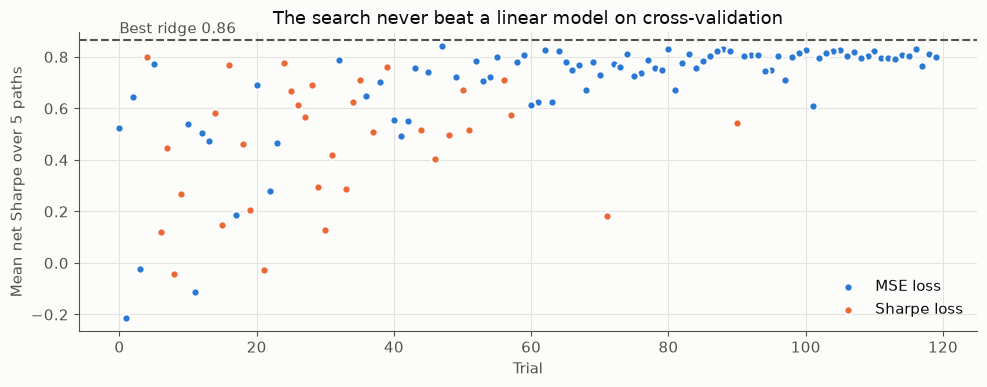

In [3]:
trials = pl.read_csv(RESULTS / "lstm_trials.csv")
ridge_trials = pl.read_csv(RESULTS / "ridge_trials.csv")
best_config = json.loads((RESULTS / "best_config.json").read_text())
print("Frozen configuration:", json.dumps(best_config, indent=2))

with pl.Config(tbl_cols=-1, tbl_width_chars=160, tbl_hide_dataframe_shape=True, float_precision=2):
    print(trials.group_by("loss").agg(
        pl.len().alias("trials"), pl.col("objective").median().alias("median_cv"), pl.col("objective").max().alias("best_cv")
    ).sort("best_cv", descending=True))
    print(trials.select("trial", "objective", "path_sharpe_min", "path_sharpe_max", "av_holding", "position_bias", "loss", "seq_len", "hidden", "layers", "epochs").head(5))

fig, ax = plt.subplots(figsize=(10, 4))
for loss, color, label in (("mse", "#2a78d6", "MSE loss"), ("sharpe", "#eb6834", "Sharpe loss")):
    subset = trials.filter(pl.col("loss") == loss)
    ax.scatter(subset["trial"], subset["objective"], s=36, color=color, edgecolor="#fcfcfb", linewidth=1.5, label=label)
ridge_best = ridge_trials["objective"][0]
ax.axhline(ridge_best, color=MUTED, linewidth=1.5, linestyle="--")
ax.annotate(f"Best ridge {ridge_best:.2f}", (0, ridge_best), xytext=(0, 5), textcoords="offset points", color=MUTED)
ax.set(title="The search never beat a linear model on cross-validation", xlabel="Trial", ylabel="Mean net Sharpe over 5 paths")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()

## Results

Everything below is walk-forward with the frozen configuration. The holdout rows are the honest comparison. In the development rows the hyperparameters were tuned on the same period, although the models themselves still only saw the past.

The ridge regression is a control. It uses the same features and the same purging, so any gap between it and the LSTM is what the recurrent network adds.

In [4]:
def load_positions(name):
    return pl.read_csv(RESULTS / name, try_parse_dates=True).select(INSTRUMENTS).to_numpy().astype(float)


STRATEGIES = {
    "LSTM": load_positions("positions_lstm.csv"),
    "Ridge": load_positions("positions_ridge.csv"),
    "Trend M=50": lib.size_positions(lib.trend_signal(MATRIX, 50), RETURNS, SIGMA),
    "EWMA M=16": lib.size_positions(lib.ewma_signal(PRICES, 16), RETURNS, SIGMA),
}
PERIODS = {"dev": (lib.WF_FIRST_TRAIN_DAY, FIRST_HOLDOUT - 1), "holdout": (FIRST_HOLDOUT, N_DAYS - 1)}
FIGURES = ["adjusted_sharpe", "sharpe", "sharpe_ex_slippage", "sharpe_1d_lag", "av_holding", "position_bias", "skewness", "kurtosis"]

rows = []
for period, (first, end) in PERIODS.items():
    for name, positions in STRATEGIES.items():
        figures = lib.slice_figures(positions, PRICES, first, end, key_figures=FIGURES)
        rows.append({"period": period, "strategy": name, **{key: float(figures[key]) for key in FIGURES}})
with pl.Config(tbl_cols=-1, tbl_rows=-1, tbl_width_chars=160, tbl_hide_dataframe_shape=True, float_precision=2):
    print(pl.DataFrame(rows))

┌─────────┬────────────┬─────────────────┬────────┬────────────────────┬───────────────┬────────────┬───────────────┬──────────┬──────────┐
│ period  ┆ strategy   ┆ adjusted_sharpe ┆ sharpe ┆ sharpe_ex_slippage ┆ sharpe_1d_lag ┆ av_holding ┆ position_bias ┆ skewness ┆ kurtosis │
│ ---     ┆ ---        ┆ ---             ┆ ---    ┆ ---                ┆ ---           ┆ ---        ┆ ---           ┆ ---      ┆ ---      │
│ str     ┆ str        ┆ f64             ┆ f64    ┆ f64                ┆ f64           ┆ f64        ┆ f64           ┆ f64      ┆ f64      │
╞═════════╪════════════╪═════════════════╪════════╪════════════════════╪═══════════════╪════════════╪═══════════════╪══════════╪══════════╡
│ dev     ┆ LSTM       ┆ 0.69            ┆ 0.71   ┆ 0.79               ┆ 0.69          ┆ 14.89      ┆ 0.17          ┆ 0.10     ┆ 4.35     │
│ dev     ┆ Ridge      ┆ 0.85            ┆ 0.88   ┆ 0.95               ┆ 0.84          ┆ 15.81      ┆ 0.01          ┆ 0.08     ┆ 4.51     │
│ dev     ┆ Trend M=

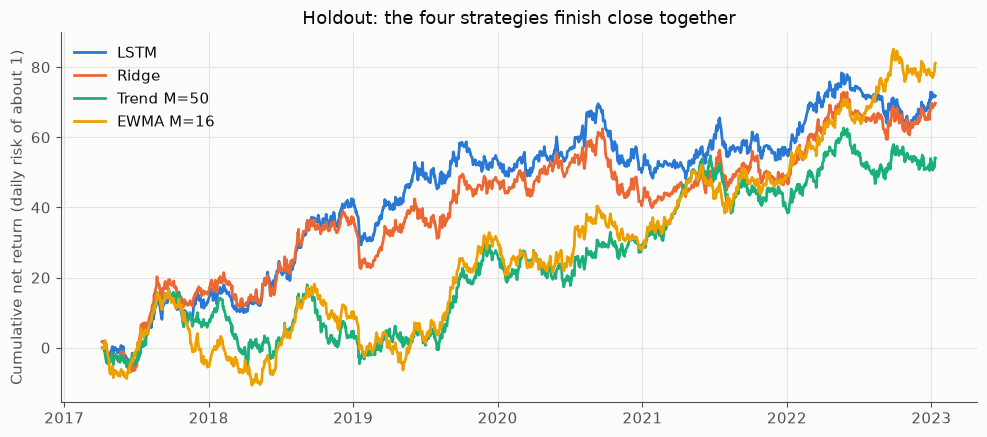

In [5]:
first, end = PERIODS["holdout"]
fig, ax = plt.subplots(figsize=(10, 4.5))
daily_holdout = {}
for name, positions in STRATEGIES.items():
    series = lib.slice_figures(positions, PRICES, first, end, key_figures=["returns"])["returns"].drop_nulls()
    daily_holdout[name] = series["returns"].to_numpy()
    cumulative = np.cumsum(daily_holdout[name])
    ax.plot(series[lib.DATE_COL].to_numpy(), cumulative, color=COLORS[name], linewidth=2, label=name)
ax.set(title="Holdout: the four strategies finish close together", ylabel="Cumulative net return (daily risk of about 1)")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()

### Are the differences real?

The holdout is under six years, so a Sharpe estimate is very noisy. The intervals below come from a block bootstrap with 20-day blocks, which keeps short-term dependence in the returns.

LSTM minus each alternative, 95% interval of the Sharpe difference:
  Ridge on the same features   -0.27 to +0.32
  Trend follower M=50          -0.58 to +0.94
  EWMA M=16                    -0.93 to +0.70


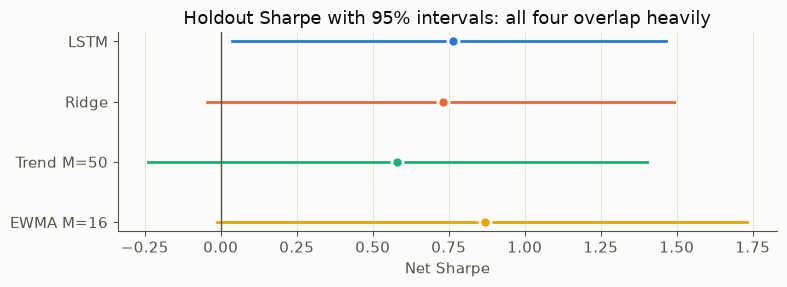

In [6]:
bootstrap = json.loads((RESULTS / "bootstrap.json").read_text())
names = {"LSTM": "LSTM", "Ridge on the same features": "Ridge", "Trend follower M=50": "Trend M=50", "EWMA M=16": "EWMA M=16"}
holdout_rows = {r["strategy"]: r for r in rows if r["period"] == "holdout"}

fig, ax = plt.subplots(figsize=(8, 3))
for y, (long_name, name) in enumerate(reversed(list(names.items()))):
    interval = bootstrap["sharpe"][long_name]
    ax.plot([interval["low"], interval["high"]], [y, y], color=COLORS[name], linewidth=2)
    ax.scatter(holdout_rows[name]["sharpe"], y, s=64, color=COLORS[name], edgecolor="#fcfcfb", linewidth=2, zorder=3)
ax.set_yticks(range(len(names)), list(reversed(list(names.values()))))
ax.axvline(0, color=MUTED, linewidth=1)
ax.grid(axis="y", visible=False)
ax.set(title="Holdout Sharpe with 95% intervals: all four overlap heavily", xlabel="Net Sharpe")
fig.tight_layout()

print("LSTM minus each alternative, 95% interval of the Sharpe difference:")
for name, interval in bootstrap["lstm_minus"].items():
    print(f"  {name:28s} {interval['low']:+.2f} to {interval['high']:+.2f}")

### What is the LSTM actually doing?

Three checks help interpret the score.

* **Long tilt.** The LSTM has a position bias of about +0.16, which the trend strategies do not have. A long-only portfolio lost money on the holdout, so market drift is not what earned its return.
* **Correlation.** The LSTM is close to the ridge regression, so it mostly learned a linear trend rule. It is much less correlated with EWMA, which is the one interesting result here.
* **Seed noise.** One network per retrain gives very different results from one seed to the next. The spread is about as large as the gaps between strategies, so averaging networks is not optional.

In [7]:
long_only = lib.size_positions(np.ones_like(MATRIX), RETURNS, SIGMA)
series = {**STRATEGIES, "Long only": long_only}
with pl.Config(tbl_cols=-1, tbl_width_chars=120, tbl_hide_dataframe_shape=True, float_precision=2):
    for period, (first, end) in PERIODS.items():
        daily = [lib.slice_figures(p, PRICES, first, end, key_figures=["returns"])["returns"]["returns"].fill_null(0).to_numpy()[5:] for p in series.values()]
        sharpe = float(lib.slice_figures(long_only, PRICES, first, end, key_figures=["sharpe"])["sharpe"])
        print(f"{period}: long-only Sharpe {sharpe:.2f}. Correlation of daily net returns:")
        print(pl.DataFrame(np.corrcoef(daily), schema=list(series)).insert_column(0, pl.Series("", list(series))))

seeds = pl.read_csv(RESULTS / "seed_stability.csv")
print("Single-network walk-forward, 10 seeds:")
print(seeds.select(
    pl.col("dev_sharpe").min().alias("dev_min"), pl.col("dev_sharpe").max().alias("dev_max"),
    pl.col("holdout_sharpe").min().alias("holdout_min"), pl.col("holdout_sharpe").mean().alias("holdout_mean"), pl.col("holdout_sharpe").max().alias("holdout_max"),
).to_dicts()[0])

dev: long-only Sharpe 0.30. Correlation of daily net returns:
┌────────────┬──────┬───────┬────────────┬───────────┬───────────┐
│            ┆ LSTM ┆ Ridge ┆ Trend M=50 ┆ EWMA M=16 ┆ Long only │
│ ---        ┆ ---  ┆ ---   ┆ ---        ┆ ---       ┆ ---       │
│ str        ┆ f64  ┆ f64   ┆ f64        ┆ f64       ┆ f64       │
╞════════════╪══════╪═══════╪════════════╪═══════════╪═══════════╡
│ LSTM       ┆ 1.00 ┆ 0.79  ┆ 0.33       ┆ 0.34      ┆ 0.22      │
│ Ridge      ┆ 0.79 ┆ 1.00  ┆ 0.41       ┆ 0.44      ┆ 0.11      │
│ Trend M=50 ┆ 0.33 ┆ 0.41  ┆ 1.00       ┆ 0.76      ┆ 0.04      │
│ EWMA M=16  ┆ 0.34 ┆ 0.44  ┆ 0.76       ┆ 1.00      ┆ 0.03      │
│ Long only  ┆ 0.22 ┆ 0.11  ┆ 0.04       ┆ 0.03      ┆ 1.00      │
└────────────┴──────┴───────┴────────────┴───────────┴───────────┘
holdout: long-only Sharpe -0.38. Correlation of daily net returns:
┌────────────┬──────┬───────┬────────────┬───────────┬───────────┐
│            ┆ LSTM ┆ Ridge ┆ Trend M=50 ┆ EWMA M=16 ┆ Long only │


### Cost sensitivity and the standard dashboard

The plan in `CLAUDE.md` asks for robustness to triple costs, so all strategies are scored at one, two and three times the base cost on the holdout.

┌────────────┬────────────────┬────────────────┬────────────────┐
│ strategy   ┆ sharpe_1x_cost ┆ sharpe_2x_cost ┆ sharpe_3x_cost │
│ ---        ┆ ---            ┆ ---            ┆ ---            │
│ str        ┆ f64            ┆ f64            ┆ f64            │
╞════════════╪════════════════╪════════════════╪════════════════╡
│ LSTM       ┆ 0.76           ┆ 0.70           ┆ 0.65           │
│ Ridge      ┆ 0.73           ┆ 0.66           ┆ 0.59           │
│ Trend M=50 ┆ 0.58           ┆ 0.49           ┆ 0.39           │
│ EWMA M=16  ┆ 0.87           ┆ 0.84           ┆ 0.81           │
└────────────┴────────────────┴────────────────┴────────────────┘


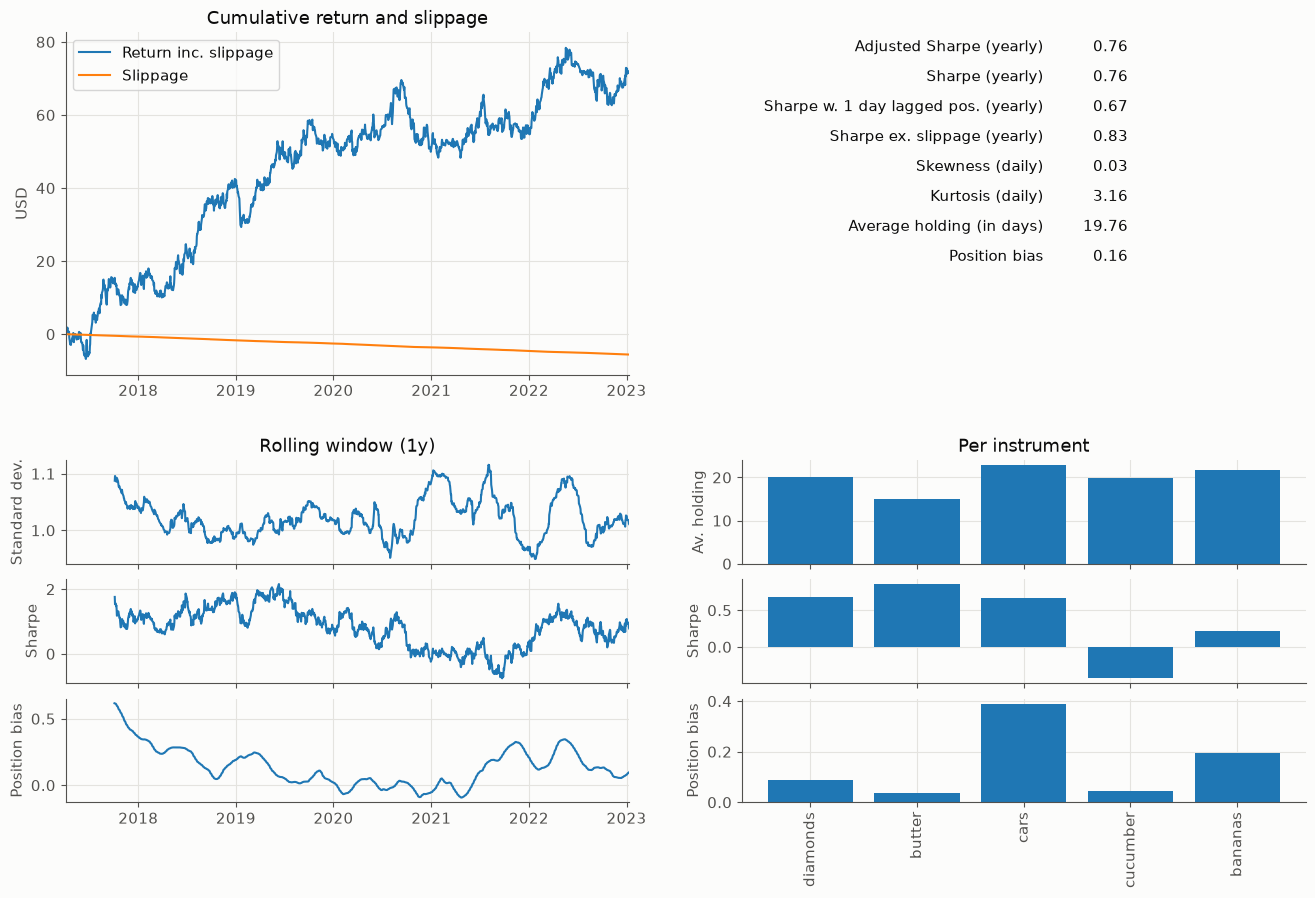

In [8]:
first, end = PERIODS["holdout"]
cost_rows = []
for name, positions in STRATEGIES.items():
    row = {"strategy": name}
    for multiple in (1, 2, 3):
        row[f"sharpe_{multiple}x_cost"] = float(lib.slice_figures(positions, PRICES, first, end, costs=-0.02 * multiple, key_figures=["sharpe"])["sharpe"])
    cost_rows.append(row)
with pl.Config(tbl_cols=-1, tbl_width_chars=120, tbl_hide_dataframe_shape=True, float_precision=2):
    print(pl.DataFrame(cost_rows))

plot_key_figures(lib.to_frame(STRATEGIES["LSTM"], PRICES)[first : end + 1], PRICES)

## Leakage and placebo tests

Lynx disqualifies leakage, so both tests from the instructions were run on the full pipeline, refitting every network on the changed data. `run_lstm.py leakage` reproduces them in about four minutes.

* **Shorter history:** positions with the last 20 days removed must equal the full run.
* **Altered future:** prices after a cut day are changed, and positions up to that day must not move. Positions after the cut must move, otherwise the test proves nothing.

The placebo shuffles the order of the days, using the same order for all assets. That removes all trend while keeping the distribution of returns and the correlation between assets. A pipeline that leaks would still show a profit here. A clean one should show roughly zero, slightly negative after costs.

In [9]:
leakage = json.loads((RESULTS / "leakage.json").read_text())
print(json.dumps(leakage, indent=2))
assert leakage["shorter_history"]["same_missing"] and leakage["shorter_history"]["max_diff_relative_to_typical_position"] == 0
assert leakage["altered_future"]["same_missing"] and leakage["altered_future"]["max_diff_relative_to_typical_position"] == 0
assert leakage["altered_future_after_cut"]["max_diff_relative_to_typical_position"] > 0
print("Leakage tests passed")

placebo = pl.read_csv(RESULTS / "placebo.csv")
print(placebo)
print(f"Mean placebo Sharpe: {placebo['sharpe'].mean():.2f}")

{
  "shorter_history": {
    "same_missing": true,
    "max_diff_relative_to_typical_position": 0.0
  },
  "altered_future": {
    "same_missing": true,
    "max_diff_relative_to_typical_position": 0.0
  },
  "altered_future_after_cut": {
    "same_missing": true,
    "max_diff_relative_to_typical_position": 31.968602587688167
  }
}
Leakage tests passed
shape: (5, 3)
┌──────┬───────────┬─────────────────┐
│ seed ┆ sharpe    ┆ adjusted_sharpe │
│ ---  ┆ ---       ┆ ---             │
│ i64  ┆ f64       ┆ f64             │
╞══════╪═══════════╪═════════════════╡
│ 0    ┆ 0.189154  ┆ 0.188385        │
│ 1    ┆ -0.375578 ┆ -0.373809       │
│ 2    ┆ -0.594228 ┆ -0.578711       │
│ 3    ┆ -0.245128 ┆ -0.243646       │
│ 4    ┆ -0.008231 ┆ -0.008232       │
└──────┴───────────┴─────────────────┘
Mean placebo Sharpe: -0.21


## Conclusion

**The LSTM is a working trend model, but it is not a better path than what you already have.** Using it as the core of the strategy is not worth it on this evidence.

* **It adds nothing over a linear model.** On the holdout it matches a ridge regression on the same features, and their returns are highly correlated. Ridge also scored at least as well in cross-validation and on the development period. So the features carry the signal, not the recurrence.
* **It does not beat the simple rule.** EWMA scored higher on both periods, with a much longer holding period and better resilience to triple costs. On the holdout it also lost nothing when lagged one extra day, while the LSTM lost about 0.09.
* **It is harder to defend.** Lynx asks for a plausible mechanism and an explanation of the code. Results also move a lot with the random seed, so explaining any one run is awkward.
* **Cross-validation was optimistic.** The best cross-validation score was above the Sharpe the same configuration achieved walk-forward on the development period, partly because cross-validation trains on future data and partly from picking the best of 120 trials.

**What is worth following up:** both models are only moderately correlated with EWMA. A simple blend of EWMA and ridge might improve on either one, and it would stay simple enough to explain. This was not tested here, and because the holdout has now been seen, it should be judged on Lynx's data or a fresh split.

**Limits of this test:**

* The example data has only 5 assets and no macro series. The event data will differ, so this verdict could change there.
* The holdout has been looked at, so any further tuning against it would no longer be honest.
* The best configuration sits at the upper edge of the search for window length and network size. The plateau is flat, so a wider search seems unlikely to change the verdict, but this was not tested.